## Одномерное уравнение адвекции-диффузии

### $$\frac{\partial \phi}{\partial t} + u \frac{\partial \phi}{\partial x} = \alpha\frac{\partial^2 \phi}{\partial x^2}. \tag{1}$$

Уравнение в частных производных вида (1) используется для моделирования ряда физических процессов, таких как теплообмен в движущейся среде, изменение концентрации вещества под действием диффузии и конвекции, и одномерное течение вязкой жидкости.
При построении разностных схем для уравнения (1) может быть важно, чтобы схема сохраняла те или иные свойства, в частности — **свойство монотонности**.

*Разностная схема называется схемой, сохраняющей монотонность численного решения (монотонной схемой), если она любую монотонную функцию $\phi^n$ переводит в монотонную на $(n + 1)$-м временном слое функцию $\phi^{n+1}$, причем с тем же направлением роста.*

Далее расмотрены три схемы:
1) Противопоточная
2) Центрально-разностная
3) Схема с отложенной коррекцией

In [95]:
import math
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

Зададим параметры задачи: скорость потока $u$, коэффициент диффузии $\alpha$, пространственный и временной шаг. 

Число Куранта: $$C = \frac{u \Delta t}{\Delta x}.$$ Число Фурье: $$Fo = \frac{\alpha \Delta t}{\Delta x^2}.$$

In [96]:
u = 1.0
alpha = 1e-4

nx = 101
L = 3.0
dx = L / (nx - 1)

dt = 0.01
t_end = 1
nt = int(t_end / dt)

Co = u * dt / dx
Fo = alpha * dt / dx**2

Зададим начальное распределение $\phi(x, 0) = \phi_0(x)$:
$$\phi_0(x) = 
\begin{cases}
1 & x \leq 1.0, \\
0 & x > 1.0.
\end{cases}$$

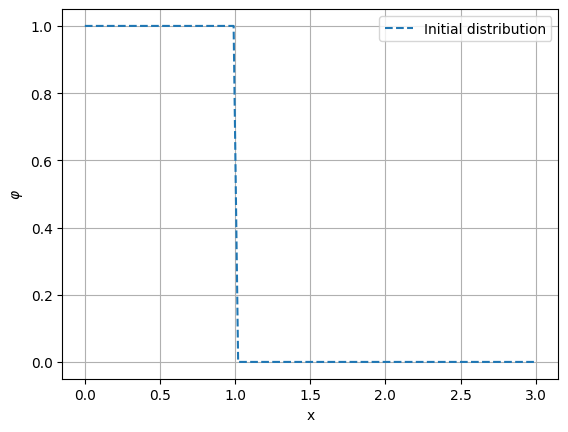

In [97]:
phi_left = 1.0
phi_right = 0.0

x = np.linspace(0, L, nx)
x0 = 1.0
phi0 = np.where(x <= x0, phi_left, phi_right)
plt.figure()
plt.plot(x, phi0, '--', label='Initial distribution')
plt.xlabel("x")
plt.ylabel(r"$\varphi$")
plt.legend()
plt.grid(True)
plt.show()

Первой реализуем неявную **противопоточную схему**:

$$\frac{\phi_i^{\,n+1}-\phi_i^{\,n}}{\Delta t}
+ u \frac{\phi_i^{\,n+1}-\phi_{i-1}^{\,n+1}}{\Delta x}
= \alpha \frac{\phi_{i+1}^{\,n+1}-2\phi_i^{\,n+1}+\phi_{i-1}^{\,n+1}}{\Delta x^2},\qquad i=1,\dots,N-2.$$

В трёхдиагональной форме:

$$- (C + \mathrm{Fo}) \, \phi_{i-1}^{\,n+1} + (1 + C + 2\mathrm{Fo}) \, \phi_i^{\,n+1} - \mathrm{Fo} \, \phi_{i+1}^{\,n+1} = \phi_i^{\,n},\qquad i=1,\dots,N-2.$$

На левой границе зададим условие Дирихле:

$$\phi(0, t) = \phi_{left}.$$

На правой границе зададим условие поглощения:

$$\frac{\partial \phi}{\partial t} (L, t)+ u \frac{\partial \phi}{\partial x} (L, t) = 0.$$

т.е. "волна" выходит за пределы области без диффузии и отражения.

Данная схема имеет порядок аппроксимации $O(\Delta t, \Delta x)$ и обладает свойством монотонности.

Теперь запишем **схему с центральными разностями** для конвективного слагаемого:

$$\frac{\phi_i^{\,n+1}-\phi_i^{\,n}}{\Delta t}
+ u \frac{\phi_{i+1}^{\,n+1}-\phi_{i-1}^{\,n+1}}{2\Delta x}
= \alpha \frac{\phi_{i+1}^{\,n+1}-2\phi_i^{\,n+1}+\phi_{i-1}^{\,n+1}}{\Delta x^2},\qquad i=1,\dots,N-2.$$

В трёхдиагональной форме:

$$\bigl(-\tfrac{C}{2} - \mathrm{Fo}\bigr)\,\phi_{i-1}^{\,n+1}
+ \bigl(1 + 2\mathrm{Fo}\bigr)\,\phi_i^{\,n+1}
+ \bigl(\tfrac{C}{2} - \mathrm{Fo}\bigr)\,\phi_{i+1}^{\,n+1}
= \phi_i^{\,n},\qquad i=1,\dots,N-2.
$$
Аналогичным образом задаются граничные условия. 

Данная схема обладает порядком аппроксимации $O(\Delta t, \Delta x^2)$, но не обладает свойством монотонности. Это связано с наличием дисперсионных слагаемых в погрешности схемы, которые могут вызывать нефизические осцилляции в окрестностях разрыва или резкого изменения решения [3]. 

*Схема с отложенной коррекцией (Deferred Correction)*

Неявная часть — противопоточная схема, явная коррекция — поток с ограничителем через каждую грань:

$$
\frac{\phi_i^{\,n+1}-\phi_i^{\,n}}{\Delta t}
+ u \frac{\phi_i^{\,n+1}-\phi_{i-1}^{\,n+1}}{\Delta x}
= \alpha \frac{\phi_{i+1}^{\,n+1}-2\phi_i^{\,n+1}+\phi_{i-1}^{\,n+1}}{\Delta x^2}
- \frac{f_{i+1/2}^{\,n} - f_{i-1/2}^{\,n}}{\Delta x},\qquad i=1,\dots,N-2.
$$

Корректирующий поток через грань $i+1/2$:

$$
f_{i+1/2}^{\,n} = u \cdot \beta_{i+1/2} \cdot (\phi_{i+1}^{\,n} - \phi_i^{\,n}).
$$

Коэффициент смешивания (для равномерной сетки $w_f = 1/2$):

$$
\beta_{i+1/2} = \min\!\left(\Phi(r_{i+1/2}) \cdot \frac{1}{2},\; 1\right).
$$

Отношение градиентов:

$$
r_{i+1/2} = \frac{\phi_i^{\,n} - \phi_{i-1}^{\,n}}{\phi_{i+1}^{\,n} - \phi_i^{\,n}}.
$$

Ограничитель потока (minmod):

$$
\Phi(r) = \max\!\bigl(0,\; \min(1,\; r)\bigr).
$$

В трёхдиагональной форме:

$$
-(C + \mathrm{Fo})\,\phi_{i-1}^{\,n+1} + (1 + C + 2\mathrm{Fo})\,\phi_i^{\,n+1} - \mathrm{Fo}\,\phi_{i+1}^{\,n+1} = \phi_i^{\,n} - C\Bigl[\beta_{i+1/2}\,(\phi_{i+1}^{\,n} - \phi_i^{\,n}) - \beta_{i-1/2}\,(\phi_i^{\,n} - \phi_{i-1}^{\,n})\Bigr].
$$

In [98]:
def build_matrix(nx, Co, Fo, scheme):
    A = np.zeros((nx, nx))
    
    A[0, 0] = 1.0
    A[nx-1, nx-1] = 1.0 + C
    A[nx-1, nx-2] = -C

    i = np.arange(1, nx - 1)
    if scheme == "upwind" or scheme == "deferred":
        A[i, i - 1] = -Co - Fo
        A[i, i] = 1 + Co + 2 * Fo
        A[i, i + 1] = -Fo
    elif scheme == "central":
        A[i, i - 1] = -0.5 * Co - Fo
        A[i, i] = 1 + 2 * Fo
        A[i, i + 1] = 0.5 * Co - Fo
    else:
        raise ValueError(f"Unknown scheme: {scheme}")

    return A

def build_rhs(nx, phi_old, phi_left, phi_right, scheme, Co=None):
    rhs = np.zeros(nx)
    rhs[0] = phi_left
    rhs[-1] = phi_right
    rhs[1:-1] = phi_old[1:-1]

    if scheme == "deferred":
        # Потоки через все внутренние грани (их nx-1 штук)
        # Грань i находится между ячейками i и i+1, i = 0, ..., nx-2
        phi_u = phi_old[:-1]   # upwind (левая ячейка)
        phi_d = phi_old[1:]    # downwind (правая ячейка)
        phi_uu = np.empty_like(phi_u)
        phi_uu[0] = phi_u[0]   # на левой границе far-upwind = upwind
        phi_uu[1:] = phi_old[:-2]
        
        num = phi_u - phi_uu
        denom = phi_d - phi_u + 1e-10
        r = num / denom
        
        limiter = np.maximum(0, np.minimum(1, r))
        
        f_corr = 0.5 * Co * limiter * (phi_d - phi_u)
        
        rhs[1:-1] += f_corr[:-1] - f_corr[1:]

    return rhs

Зададим аналитическое решение (без учёта правой границы):

In [99]:
def analytical_solution(x, t, u, alpha, phi_left, x0):
    y = x - x0
    w = (y - u * t) / np.sqrt(t)
    if alpha > 0:
        return phi_left * 0.5 * (1 - sp.special.erf(w * 0.5 / alpha**0.5))
    else:
        return np.where(x < x0, phi_left, 0.0)
phi_analytical = analytical_solution(x, t_end, u, alpha, phi_left, x0)

Найдём решение каждой из трёх схем:

In [100]:
results = {"analytical": phi_analytical}
for scheme in ["upwind", "central", "deferred"]:
    A = build_matrix(nx, Co, Fo, scheme)
    phi_old = phi0.copy()
    phi = phi0.copy()
    for _ in range(nt):
        rhs = build_rhs(nx, phi_old, phi_left, phi_right, scheme, Co)
        phi = sp.linalg.solve(A, rhs, assume_a="tridiagonal", check_finite=False)
        phi_old[:] = phi
    results[scheme] = phi
        

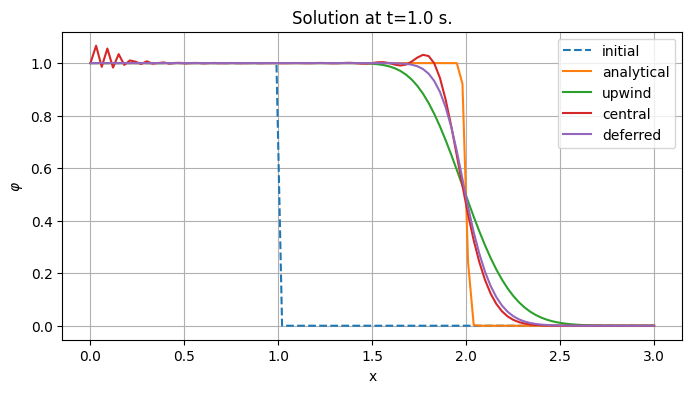

In [101]:
plt.figure(figsize=(8, 4))
plt.plot(x, phi0, '--', label="initial")
for name, result in results.items():
    plt.plot(x, result, label=name)
plt.legend()
plt.xlabel("x")
plt.ylabel(r"$\varphi$")
plt.title(f"Solution at t={t_end:.1f} s.")
plt.grid(True)
plt.show()

Центрально-разностная схема демонстрирует немонотонное поведение (это связано в первую очередь с резким скачком в начальном распределении, на гладких решениях эта схема ведет себя монотонно).

Далее вычислим отклонение от аналитического решения в L2 норме:

In [93]:
for scheme in ["upwind", "central", "deferred"]:
    r = results[scheme]
    print(f"L2 error {scheme}: {np.linalg.norm(r[1:-1] - phi_analytical[1:-1]):.2f}")

L2 error upwind: 1.15
L2 error central: 0.79
L2 error deferred: 0.83


Таким образом, для заданных параметров наименьшую погрешность даёт схема с центральными разностями, наибольшую - противопоточная.